# Modelado supervisado — Predicción de Popularidad de Canciones en Spotify
### Evaluación Parcial N°2 — MLY1101 Machine Learning

Este notebook cubre las etapas de **Modelado** y **Evaluación** de CRISP-DM. Como `popularity` es una variable numérica (0-100), el problema es de **regresión**. Se comparan dos modelos supervisados contra una línea base:

| Modelo | Rol | Justificación |
|---|---|---|
| Baseline (media) | Referencia mínima | Si un modelo no supera predecir siempre el promedio, no aporta valor. |
| Regresión lineal | Modelo base interpretable | Simple y rápido; permite saber cuánto se explica con relaciones lineales. |
| Gradient Boosting | Modelo más potente | Captura relaciones no lineales e interacciones (p. ej. género × audio features), que el EDA sugería porque las correlaciones lineales eran débiles. |

Usa el dataset de `01_preparacion_datos.ipynb` (una fila por canción, géneros en multi-hot).

## 5. Modelado

### 5.1 Carga de datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split, GroupShuffleSplit, GroupKFold, RandomizedSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_style('whitegrid')
RANDOM_STATE = 42

df = pd.read_csv('../data/processed/spotify_tracks_clean.csv')
genre_cols = [c for c in df.columns if c.startswith('genre_')]
print(df.shape)

import sklearn
print('Versiones -> pandas', pd.__version__, '| numpy', np.__version__, '| scikit-learn', sklearn.__version__)

(89740, 133)
Versiones -> pandas 3.0.2 | numpy 2.4.4 | scikit-learn 1.8.0


### 5.2 Variables predictoras y partición entrenamiento / prueba

- **Predictores (128):** 13 audio features, `explicit` y las 114 columnas `genre_*`.
- **Se excluyen** `track_id`, `track_name`, `artists` y `album_name`: son identificadores/texto, no características de la canción, y usarlos haría que el modelo memorice en vez de generalizar.
- **Partición 80/20 por artista** (`GroupShuffleSplit`, semilla fija): ningún artista aparece a la vez en entrenamiento y en prueba. Con una partición aleatoria por canción, el mismo artista (e incluso la misma canción publicada en un álbum, un single y un recopilatorio con distinto `track_id`) quedaba a ambos lados y el modelo se evaluaba reconociendo artistas ya vistos en vez de generalizando a artistas nuevos. En la sección 5.5 se comparan las dos particiones.
- **Limitación:** el grupo es el texto exacto de la columna `artists`; una colaboración ("A;B") cuenta como un grupo distinto de "A", por lo que aún puede quedar algún artista en ambos lados.
- **`key` y `mode` como numéricas:** para Gradient Boosting no es problema (los árboles dividen por umbrales); en la regresión lineal, `key` (0-11, nota musical) supone un efecto lineal sobre el número de la nota, una simplificación. Su efecto es prácticamente nulo (sección 6.5), por lo que no se transforma.
- **Predicciones recortadas a 0-100:** `popularity` solo existe entre 0 y 100, así que las predicciones fuera de ese rango se recortan a esos límites (secciones 5.3 y 5.4).

In [2]:
audio_cols = ['duration_ms', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness',
              'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature']

X = df[audio_cols + ['explicit'] + genre_cols].copy()
X['explicit'] = X['explicit'].astype(int)
y = df['popularity']

# Partición por artista: todas las canciones de un mismo artista quedan en el mismo conjunto
grupos = df['artists']
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
idx_train, idx_test = next(gss.split(X, y, groups=grupos))
X_train, X_test = X.iloc[idx_train], X.iloc[idx_test]
y_train, y_test = y.iloc[idx_train], y.iloc[idx_test]
grupos_train = grupos.iloc[idx_train]

print('Predictores:', X.shape[1], '| train:', X_train.shape[0], '| test:', X_test.shape[0])
print('Artistas en común entre train y test:', len(set(grupos_train) & set(grupos.iloc[idx_test])))

Predictores: 128 | train: 72065 | test: 17675
Artistas en común entre train y test: 0


### 5.3 Línea base y regresión lineal

Métricas usadas (en unidades de `popularity`, escala 0-100):
- **RMSE:** error típico, penaliza más los errores grandes.
- **MAE:** error absoluto promedio, fácil de explicar al negocio.
- **R²:** proporción de la variabilidad de `popularity` que explica el modelo (0 = nada, 1 = todo).

In [3]:
def metricas(y_real, y_pred):
    return {'RMSE': mean_squared_error(y_real, y_pred) ** 0.5,
            'MAE': mean_absolute_error(y_real, y_pred),
            'R2': r2_score(y_real, y_pred)}

resultados = {}
pred_base = np.full(len(y_test), y_train.mean())
resultados['Baseline (media)'] = metricas(y_test, pred_base)
resultados['Baseline (media)']

{'RMSE': 20.81327279129565, 'MAE': 17.483809808271666, 'R2': -0.0002783159010792957}

In [4]:
lin = LinearRegression().fit(X_train, y_train)
pred_lin_bruta = lin.predict(X_test)
pred_lin = np.clip(pred_lin_bruta, 0, 100)   # popularity solo toma valores entre 0 y 100
print('Predicciones fuera de 0-100 recortadas (regresión lineal):', int(((pred_lin_bruta < 0) | (pred_lin_bruta > 100)).sum()))
resultados['Regresión lineal'] = metricas(y_test, pred_lin)
resultados['Regresión lineal']

Predicciones fuera de 0-100 recortadas (regresión lineal): 63


{'RMSE': 17.218399477257957, 'MAE': 12.316799399482315, 'R2': 0.3154177090367082}

### 5.4 Gradient Boosting

Se usa `HistGradientBoostingRegressor` de scikit-learn, una implementación de gradient boosting sobre árboles que entrena mucho más rápido en datasets grandes (≈ 90.000 filas). Los hiperparámetros se eligen con **búsqueda aleatoria (15 combinaciones) y validación cruzada de 3 particiones agrupadas por artista (`GroupKFold`) sobre el conjunto de entrenamiento**, así el conjunto de prueba solo se usa para la evaluación final. La búsqueda tarda unos 10-15 minutos en un solo núcleo (menos en un computador con varios núcleos).

- `learning_rate`, `max_iter`: velocidad de aprendizaje y número de árboles. Se fija `early_stopping=False` para que el número de árboles lo decida la búsqueda y no una validación interna al azar (que mezclaría artistas).
- `max_depth`, `max_leaf_nodes`, `min_samples_leaf`: complejidad de cada árbol (controlan el sobreajuste).
- `l2_regularization`: penalización para suavizar el modelo.

In [5]:
param_dist = {
    'learning_rate': [0.03, 0.05, 0.1],
    'max_iter': [200, 400, 600],
    'max_depth': [None, 8, 12],
    'max_leaf_nodes': [15, 31, 63],
    'min_samples_leaf': [50, 100, 200, 400],
    'l2_regularization': [1, 10, 30, 100],
}
# early_stopping=False: el número de árboles lo decide la búsqueda (max_iter), no una validación interna al azar
busqueda = RandomizedSearchCV(
    HistGradientBoostingRegressor(random_state=RANDOM_STATE, early_stopping=False),
    param_distributions=param_dist, n_iter=15, cv=GroupKFold(n_splits=3),
    scoring='neg_root_mean_squared_error', random_state=RANDOM_STATE, n_jobs=-1)
busqueda.fit(X_train, y_train, groups=grupos_train)

gb = busqueda.best_estimator_
print('Mejores hiperparámetros:', busqueda.best_params_)
print('RMSE en validación cruzada por artista (train):', round(-busqueda.best_score_, 3))

pred_gb_bruta = gb.predict(X_test)
pred_gb = np.clip(pred_gb_bruta, 0, 100)
print('Predicciones fuera de 0-100 recortadas (Gradient Boosting):', int(((pred_gb_bruta < 0) | (pred_gb_bruta > 100)).sum()))
resultados['Gradient Boosting'] = metricas(y_test, pred_gb)
resultados['Gradient Boosting']

Mejores hiperparámetros: {'min_samples_leaf': 200, 'max_leaf_nodes': 63, 'max_iter': 400, 'max_depth': None, 'learning_rate': 0.03, 'l2_regularization': 10}
RMSE en validación cruzada por artista (train): 16.301
Predicciones fuera de 0-100 recortadas (Gradient Boosting): 12


{'RMSE': 16.844297853608257, 'MAE': 11.846548985240199, 'R2': 0.3448421845349555}

**Resultado de la búsqueda:** la mejor configuración (`learning_rate=0.03`, `max_iter=400`, `max_leaf_nodes=63`, `max_depth=None`, `min_samples_leaf=200`, `l2_regularization=10`) tiene un RMSE de validación cruzada por artista de 16,30 y un RMSE de prueba de 16,84. Una búsqueda previa más pequeña (8 combinaciones, 5 hiperparámetros) había dado 16,29 en validación cruzada y 16,84 en prueba: **ampliar la búsqueda no mejoró el modelo**. El rendimiento se estabiliza en una meseta, lo que sugiere que el límite está en la información disponible (género y audio features) y no en el ajuste de hiperparámetros. Dos valores quedaron en el borde de la grilla (`learning_rate=0.03` y `max_leaf_nodes=63`), pero la diferencia entre ambas búsquedas fue de solo 0,015 de RMSE.

Las predicciones se recortan al rango 0-100: 12 de Gradient Boosting y 63 de la regresión lineal eran negativas (la regresión lineal llegó a -23,7).

### 5.5 ¿Por qué partir por artista? Comparación con la partición aleatoria

Se entrenan los dos modelos, con los mismos hiperparámetros, con una partición aleatoria por canción y con la partición por artista. `R2 train` sirve para ver el sobreajuste (la brecha con el R² de prueba). `% canciones con artista ya visto` mide qué parte de la prueba tiene un artista que también está en el entrenamiento, y `% con misma canción en train` cuántas canciones de la prueba tienen otra versión (mismo artista y mismo nombre, otro `track_id`) en el entrenamiento.

In [6]:
filas = []
particiones = {
    'Aleatoria por canción': train_test_split(X.index, test_size=0.2, random_state=RANDOM_STATE),
    'Por artista (usada)': (X_train.index, X_test.index),
}
clave = df['artists'] + '||' + df['track_name']
for nombre_part, (i_tr, i_te) in particiones.items():
    Xtr, Xte, ytr, yte = X.loc[i_tr], X.loc[i_te], y.loc[i_tr], y.loc[i_te]
    visto = df.loc[i_te, 'artists'].isin(set(df.loc[i_tr, 'artists'])).mean() * 100
    repetida = clave.loc[i_te].isin(set(clave.loc[i_tr])).mean() * 100
    modelos_5_5 = {'Regresión lineal': LinearRegression().fit(Xtr, ytr),
                   'Gradient Boosting': HistGradientBoostingRegressor(**gb.get_params()).fit(Xtr, ytr)}
    for nombre_mod, mod in modelos_5_5.items():
        m = metricas(yte, np.clip(mod.predict(Xte), 0, 100))
        filas.append({'Partición': nombre_part, 'Modelo': nombre_mod, 'RMSE': m['RMSE'], 'MAE': m['MAE'],
                      'R2 test': m['R2'], 'R2 train': r2_score(ytr, np.clip(mod.predict(Xtr), 0, 100)),
                      '% canciones con artista ya visto': visto, '% con misma canción en train': repetida})
comparacion_split = pd.DataFrame(filas).round(3)
comparacion_split

,Partición,Modelo,RMSE,MAE,R2 test,R2 train,% canciones con artista ya visto,% con misma canción en train
0,Aleatoria por canción,Regresión lineal,16.485,11.785,0.350,0.360,75.251,13.444
1,Aleatoria por canción,Gradient Boosting,15.480,10.891,0.427,0.493,75.251,13.444
2,Por artista (usada),Regresión lineal,17.218,12.317,0.315,0.366,0.000,0.000
3,Por artista (usada),Gradient Boosting,16.844,11.847,0.345,0.497,0.000,0.000


**Lectura:**
- Con la partición aleatoria, **75% de las canciones de prueba tienen un artista que también está en el entrenamiento** y 13% tienen otra versión de la misma canción (mismo artista y nombre, otro `track_id`: álbum, single, recopilatorio). Con la partición por artista ambos porcentajes son 0.
- El efecto es mayor en el modelo más flexible: el R² de prueba de Gradient Boosting baja de 0,427 a 0,345 (RMSE 15,48 a 16,84) y el de la regresión lineal de 0,350 a 0,315 (RMSE 16,49 a 17,22). Conocer al artista ayuda sobre todo a un modelo capaz de memorizar.
- **Por eso se usa la partición por artista:** mide lo que le importa al negocio, que es predecir canciones de artistas que el modelo no ha visto. Las cifras son más bajas, pero más honestas; no deben compararse con trabajos que usan una partición aleatoria.
- **Sobreajuste:** con la partición por artista, Gradient Boosting tiene R² de 0,497 en entrenamiento contra 0,345 en prueba (brecha 0,15); la regresión lineal 0,366 contra 0,315 (brecha 0,05). Con la partición aleatoria la brecha de Gradient Boosting era solo 0,07: parte de lo que el modelo "sabía" era el artista. La búsqueda de hiperparámetros lo limita con regularización (`min_samples_leaf=200`, `l2_regularization=10`).

## 6. Evaluación

### 6.1 Comparación de modelos y gráfico real vs predicho

,RMSE,MAE,R2
Baseline (media),20.813,17.484,0.000
Regresión lineal,17.218,12.317,0.315
Gradient Boosting,16.844,11.847,0.345


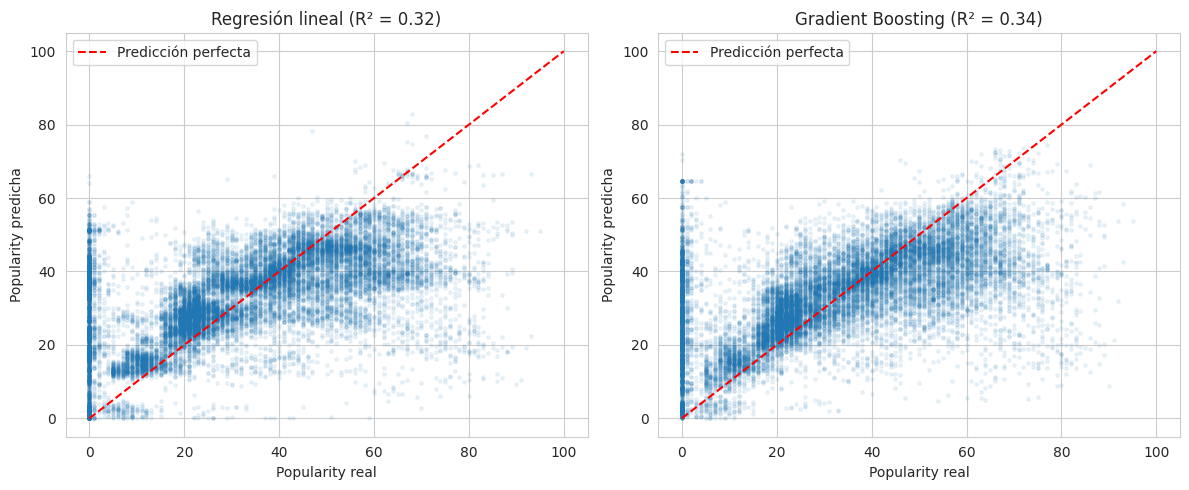

In [7]:
tabla = pd.DataFrame(resultados).T.round(3)
tabla['R2'] = tabla['R2'] + 0.0   # evita mostrar -0.0 en la línea base
display(tabla) if 'display' in globals() else print(tabla)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, pred, nombre in zip(axes, [pred_lin, pred_gb], ['Regresión lineal', 'Gradient Boosting']):
    ax.scatter(y_test, pred, alpha=0.08, s=6)
    ax.plot([0, 100], [0, 100], 'r--', label='Predicción perfecta')
    ax.set_xlabel('Popularity real'); ax.set_ylabel('Popularity predicha')
    ax.set_title(f'{nombre} (R² = {r2_score(y_test, pred):.2f})')
    ax.legend()
plt.tight_layout()
plt.savefig('../images/real_vs_predicho.png', dpi=100)
plt.show()

**Lectura de los resultados (conjunto de prueba, partición por artista):**

| Modelo | RMSE | MAE | R² |
|---|---|---|---|
| Baseline (media) | 20,81 | 17,48 | 0,000 |
| Regresión lineal | 17,22 | 12,32 | 0,315 |
| Gradient Boosting | **16,84** | **11,85** | **0,345** |

- Ambos modelos superan la línea base (RMSE -17% la regresión lineal y -19% Gradient Boosting): el género y las audio features sí contienen señal sobre la popularidad.
- **Gradient Boosting mejora a la regresión lineal en las tres métricas, pero la mejora es modesta** (RMSE -0,37 puntos, MAE -0,47 puntos, R² de 0,315 a 0,345). Con la partición aleatoria por canción la diferencia parecía mayor (sección 5.5) porque el modelo flexible aprovechaba canciones casi idénticas del mismo artista; con artistas nuevos esa ventaja se reduce.
- **R² ≈ 0,35**: ≈ 65% de la variabilidad de `popularity` no se explica. Es coherente con la hipótesis del EDA: faltan factores externos (artista, promoción, fecha de lanzamiento) que no están en el dataset, y al evaluar con artistas nuevos el modelo no puede apoyarse en la identidad del artista.
- En promedio el mejor modelo se equivoca por ≈ 11,8 puntos de popularidad (MAE), sobre una escala 0-100.
- En el gráfico, si el modelo fuera perfecto los puntos estarían sobre la línea roja. Las predicciones se concentran en la zona media y las canciones con popularidad real muy alta o igual a 0 se predicen peor; Gradient Boosting se acerca algo más a la diagonal que la regresión lineal.

### 6.2 Evaluación del KPI de negocio: canciones "top" (popularity > 70)

El segundo KPI definido en la sección 3 del README es identificar las canciones top. Solo ≈ 3% de las canciones lo son, así que se mide con **recall** (de las top reales, cuántas detecta) y **precisión** (de las que marca como top, cuántas lo son), según el umbral de predicción, y con un enfoque más realista para una distribuidora: **priorizar el 10% de canciones con mayor predicción**.

In [8]:
real_top = (y_test > 70)
print('Canciones top en test:', real_top.sum(), f'({real_top.mean():.1%})\n')

filas = []
for nombre, pred in [('Regresión lineal', pred_lin), ('Gradient Boosting', pred_gb)]:
    for umbral in [70, 60, 50]:
        pred_top = pred > umbral
        tp = (pred_top & real_top).sum()
        filas.append({'Modelo': nombre, 'Umbral predicho >': umbral,
                      'Canciones marcadas': pred_top.sum(),
                      'Recall (top detectadas)': tp / real_top.sum(),
                      'Precisión': tp / max(pred_top.sum(), 1)})
kpi = pd.DataFrame(filas).round(3)
print(kpi.to_string(index=False))

# Priorizar el 10% de canciones con mayor popularidad predicha
n10 = int(len(y_test) * 0.10)
for nombre, pred in [('Regresión lineal', pred_lin), ('Gradient Boosting', pred_gb)]:
    idx = np.argsort(pred)[::-1][:n10]
    print(f'{nombre}: al priorizar el 10% con mayor predicción se captura {real_top.values[idx].sum() / real_top.sum():.1%} de las canciones top')

Canciones top en test: 550 (3.1%)

           Modelo  Umbral predicho >  Canciones marcadas  Recall (top detectadas)  Precisión
 Regresión lineal                 70                   7                    0.002      0.143
 Regresión lineal                 60                  77                    0.038      0.273
 Regresión lineal                 50                1155                    0.198      0.094
Gradient Boosting                 70                  26                    0.011      0.231
Gradient Boosting                 60                 204                    0.085      0.230
Gradient Boosting                 50                1532                    0.273      0.098
Regresión lineal: al priorizar el 10% con mayor predicción se captura 23.5% de las canciones top
Gradient Boosting: al priorizar el 10% con mayor predicción se captura 28.9% de las canciones top


**Interpretación para el negocio:**
- Con el umbral estricto (predicho > 70) Gradient Boosting casi no marca canciones (26 de ~17.700) y **detecta alrededor del 1% de las top** (recall 1,1%, precisión 23%). Los modelos de regresión tienden a predecir hacia el promedio y rara vez llegan a valores extremos.
- Como herramienta de **priorización**, el modelo es más útil: si la distribuidora promociona solo el 10% de canciones con mayor predicción, **captura ~29% de las canciones top** (la regresión lineal captura ~23%; elegir al azar capturaría ~10%). Es decir, concentra ~2,9 veces más canciones exitosas que el azar.
- Conclusión: el modelo sirve para **ordenar y priorizar candidatas**, no para asegurar que una canción será un éxito.

### 6.3 Evaluación gráfica del KPI de canciones top

El KPI de negocio es detectar canciones **top** (`popularity > 70`), una clase escasa (≈ 3%). Como los modelos son de regresión, el KPI se evalúa convirtiéndolo en una **clasificación binaria**: la canción es "top" real si `popularity > 70` y se marca como "top" predicha si la predicción supera un umbral. Con eso se pueden usar matrices de confusión, curvas ROC / precisión-recall y una curva de ganancia acumulada.

Los modelos **no se vuelven a entrenar**: se usan las mismas predicciones sobre el conjunto de prueba de las secciones anteriores.

           Modelo  Umbral    TN   FP  FN  TP  Recall  Precisión
 Regresión lineal      60 17069   56 529  21   0.038      0.273
Gradient Boosting      60 16968  157 503  47   0.085      0.230
 Regresión lineal      50 16079 1046 441 109   0.198      0.094
Gradient Boosting      50 15743 1382 400 150   0.273      0.098


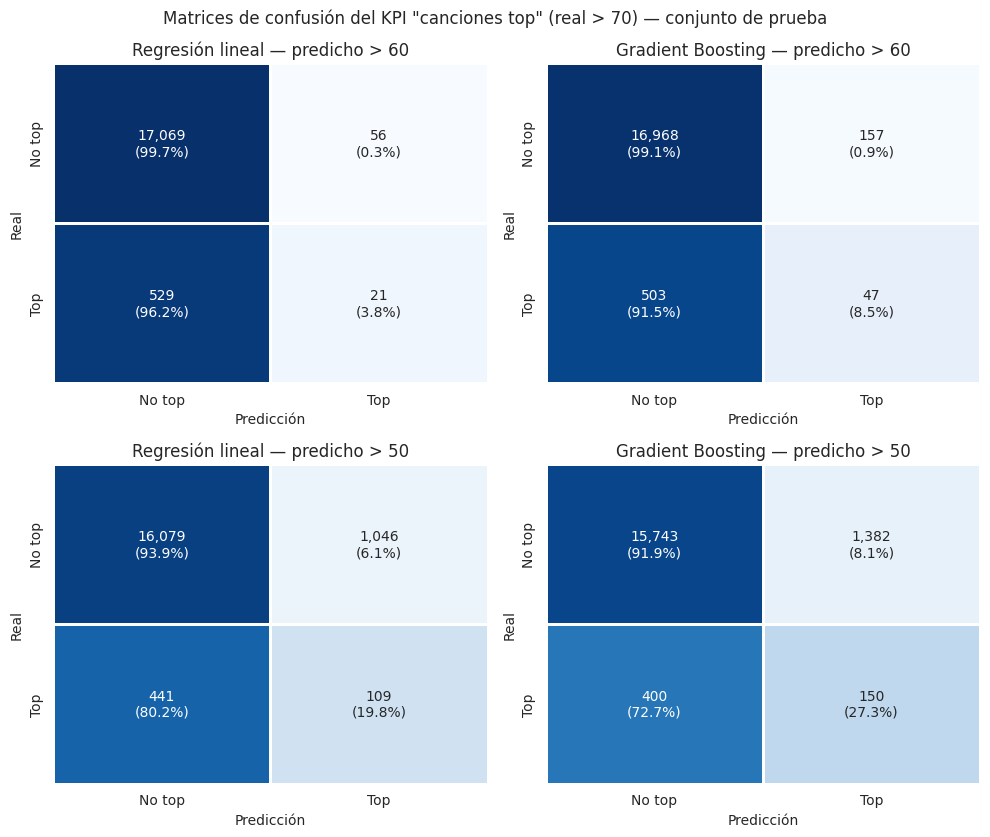

In [9]:
# Convertimos el KPI a clasificación binaria: "top" real (popularity > 70) vs "top" predicho (predicción > umbral).
# Se usan umbrales 60 y 50 porque con 70 los modelos casi no marcan canciones.
# Cada celda muestra el conteo y, entre paréntesis, el % de su fila (la fila suma 100%); el color sigue ese %,
# así las canciones top (clase escasa) no quedan invisibles frente a las no top.
from sklearn.metrics import confusion_matrix

modelos_pred = {'Regresión lineal': pred_lin, 'Gradient Boosting': pred_gb}
umbrales = [60, 50]
etiquetas = ['No top', 'Top']

fig, axes = plt.subplots(len(umbrales), 2, figsize=(10, 8.5))
filas = []
for i, u in enumerate(umbrales):
    for j, (nombre, pred) in enumerate(modelos_pred.items()):
        cm = confusion_matrix(real_top, pred > u)
        cm_pct = cm / cm.sum(axis=1, keepdims=True)
        anotaciones = np.array([[f'{cm[a, b]:,}\n({cm_pct[a, b]:.1%})' for b in range(2)] for a in range(2)])
        sns.heatmap(cm_pct, annot=anotaciones, fmt='', cmap='Blues', vmin=0, vmax=1, cbar=False,
                    xticklabels=etiquetas, yticklabels=etiquetas, ax=axes[i, j], linewidths=1, linecolor='white')
        axes[i, j].set_title(f'{nombre} — predicho > {u}')
        axes[i, j].set_xlabel('Predicción'); axes[i, j].set_ylabel('Real')
        tn, fp, fn, tp = cm.ravel()
        filas.append({'Modelo': nombre, 'Umbral': u, 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
                      'Recall': tp / (tp + fn), 'Precisión': tp / (tp + fp)})
fig.suptitle('Matrices de confusión del KPI "canciones top" (real > 70) — conjunto de prueba')
plt.tight_layout()
plt.savefig('../images/matrices_confusion_top.png', dpi=100)
plt.show()
print(pd.DataFrame(filas).round(3).to_string(index=False))

**Lectura de las matrices de confusión** (el % entre paréntesis es el de la fila, o sea, el de la celda "Top" / "Top" es el **recall**):

- Con el umbral 60, Gradient Boosting detecta **47 de las 550 canciones top (8,5%)** con 157 falsas alarmas (precisión 23,0%). La regresión lineal detecta solo 21 (3,8%).
- Con el umbral 50 sube el recall (GB: 150 canciones, 27,3%; lineal: 109, 19,8%), pero a costa de más falsas alarmas: GB marca 1.532 canciones y solo 150 son top (precisión 9,8%).
- Es el compromiso típico entre **recall y precisión**: bajar el umbral encuentra más éxitos, pero obliga a promocionar más canciones que no lo serán. Gradient Boosting detecta más canciones top que la regresión lineal en los dos umbrales.
- Aun así, ningún umbral logra detectar la mayoría de las top: los modelos de regresión predicen hacia el promedio y casi nunca llegan a valores altos.

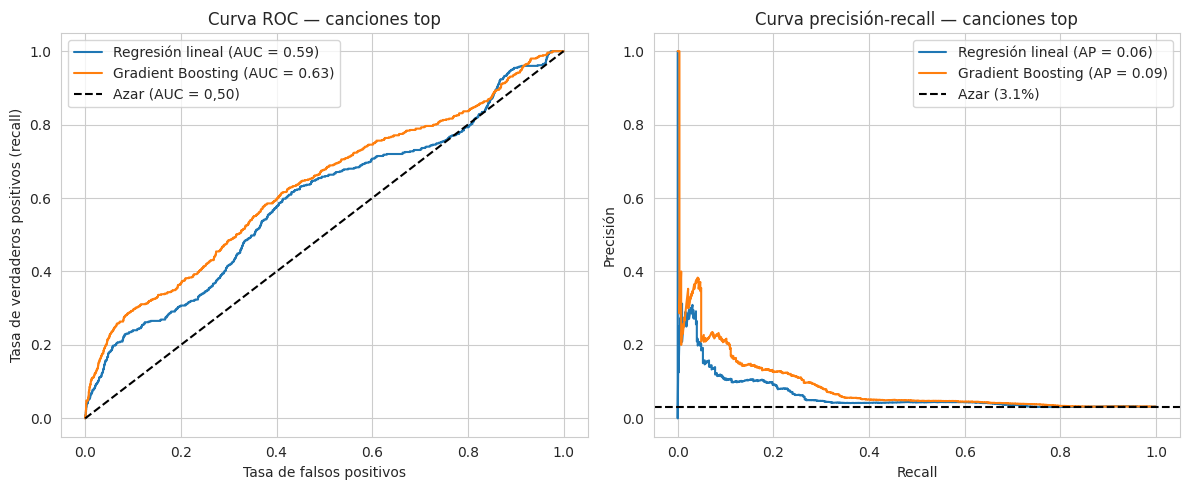

In [10]:
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, average_precision_score

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for nombre, pred in modelos_pred.items():
    fpr, tpr, _ = roc_curve(real_top, pred)
    axes[0].plot(fpr, tpr, label=f'{nombre} (AUC = {roc_auc_score(real_top, pred):.2f})')
    prec, rec, _ = precision_recall_curve(real_top, pred)
    axes[1].plot(rec, prec, label=f'{nombre} (AP = {average_precision_score(real_top, pred):.2f})')
axes[0].plot([0, 1], [0, 1], 'k--', label='Azar (AUC = 0,50)')
axes[0].set_xlabel('Tasa de falsos positivos'); axes[0].set_ylabel('Tasa de verdaderos positivos (recall)')
axes[0].set_title('Curva ROC — canciones top'); axes[0].legend()
axes[1].axhline(real_top.mean(), color='k', linestyle='--', label=f'Azar ({real_top.mean():.1%})')
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precisión')
axes[1].set_title('Curva precisión-recall — canciones top'); axes[1].legend()
plt.tight_layout()
plt.savefig('../images/roc_precision_recall_top.png', dpi=100)
plt.show()

**Lectura de las curvas ROC y precisión-recall:**

- **AUC = 0,63 para Gradient Boosting y 0,59 para la regresión lineal** (azar = 0,50): usando la predicción como puntaje, el modelo ordena las canciones solo algo mejor que el azar; la capacidad de separar top de no top es **limitada**.
- En la curva precisión-recall, GB queda por encima de la lineal y del azar (3,1%, que es la proporción de canciones top), pero su área (AP = 0,09 vs 0,06 de la lineal) es baja: la precisión cae rápido apenas se pide más recall. Con una clase tan escasa esta curva es más exigente que la ROC, y confirma que el modelo sirve como apoyo de priorización, no como detector confiable.

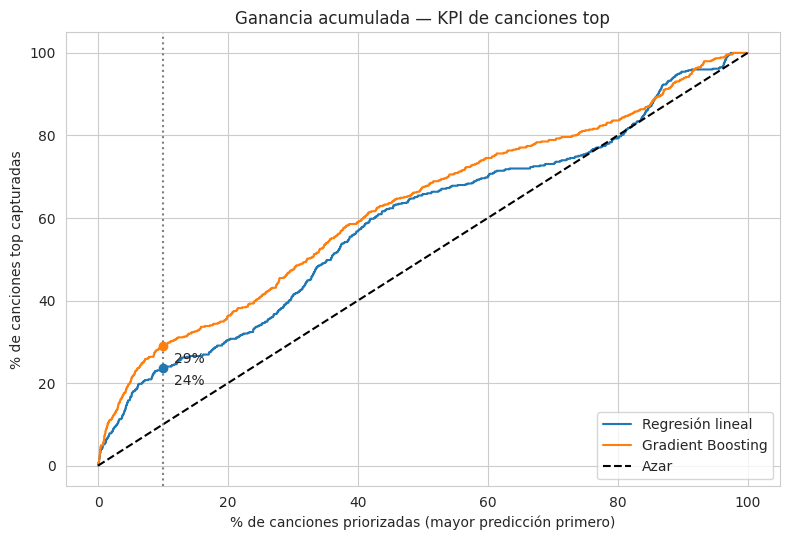

In [11]:
# Ganancia acumulada: si se promociona el X% de canciones con mayor predicción, ¿qué % de las top se captura?
def ganancia_acumulada(pred):
    orden = np.argsort(pred)[::-1]
    acum = np.cumsum(real_top.values[orden]) / real_top.sum()
    x = np.arange(1, len(pred) + 1) / len(pred)
    return x, acum

plt.figure(figsize=(8, 5.5))
for nombre, pred in modelos_pred.items():
    x, acum = ganancia_acumulada(pred)
    plt.plot(x * 100, acum * 100, label=nombre)
    k = int(len(x) * 0.10)
    plt.scatter([10], [acum[k] * 100], zorder=5)
    plt.annotate(f'{acum[k]:.0%}', (10, acum[k] * 100), textcoords='offset points', xytext=(8, -12))
plt.plot([0, 100], [0, 100], 'k--', label='Azar')
plt.axvline(10, color='gray', linestyle=':')
plt.xlabel('% de canciones priorizadas (mayor predicción primero)')
plt.ylabel('% de canciones top capturadas')
plt.title('Ganancia acumulada — KPI de canciones top')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('../images/ganancia_acumulada.png', dpi=100)
plt.show()

**Lectura de la ganancia acumulada:**

- Si la distribuidora promociona solo el **10% de canciones con mayor predicción**, Gradient Boosting captura el **29% de las canciones top** (regresión lineal: 23%); al azar se capturaría 10%. Es decir, concentra ≈ 2,9 veces más éxitos que elegir sin modelo.
- En los cortes habituales (5%, 10% y 20% de canciones priorizadas) la curva de Gradient Boosting queda por encima de la regresión lineal y del azar (20%, 29% y 36% de las top, contra 17%, 23% y 30% de la lineal), lo que respalda usar el modelo para **ordenar y priorizar candidatas**.

### 6.4 Comparación visual de métricas y análisis de errores

Estos gráficos responden dos preguntas: ¿cuánto mejora cada modelo respecto a la línea base? y ¿**dónde** se equivoca el mejor modelo?

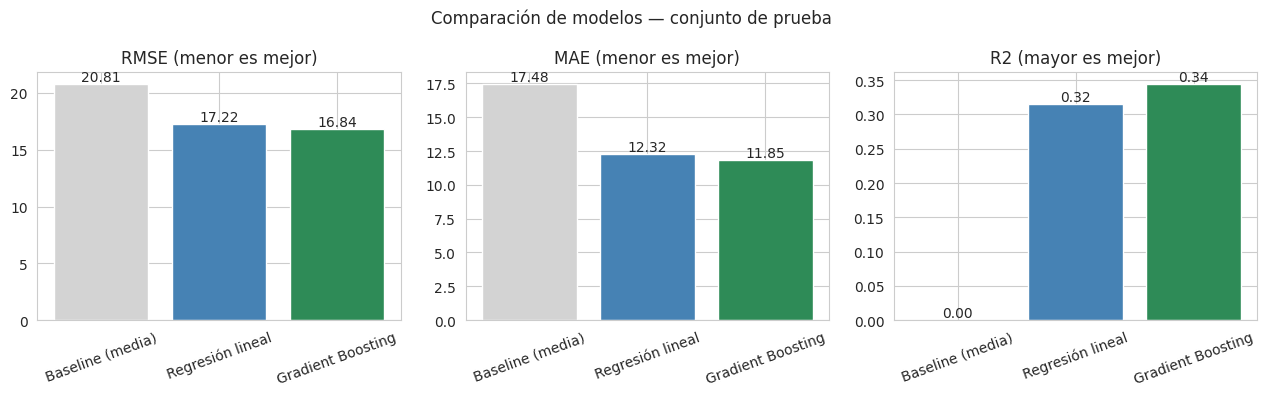

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
colores = ['lightgray', 'steelblue', 'seagreen']
for ax, metrica in zip(axes, ['RMSE', 'MAE', 'R2']):
    valores = tabla[metrica]
    barras = ax.bar(valores.index, valores.values, color=colores)
    ax.set_title(metrica + (' (menor es mejor)' if metrica != 'R2' else ' (mayor es mejor)'))
    ax.tick_params(axis='x', rotation=20)
    for b, v in zip(barras, valores.values):
        v = 0.0 if abs(v) < 0.005 else v   # evita mostrar "-0.00" en la línea base
        ax.annotate(f'{v:.2f}', (b.get_x() + b.get_width() / 2, max(v, 0)), ha='center', va='bottom')
plt.suptitle('Comparación de modelos — conjunto de prueba')
plt.tight_layout()
plt.savefig('../images/comparacion_metricas.png', dpi=100)
plt.show()

**Lectura:** Gradient Boosting reduce el RMSE de 20,81 (línea base) a 16,84, una mejora de ≈ 19% (la regresión lineal: 17,22, ≈ 17%), y supera a la regresión lineal en las tres métricas, aunque por un margen pequeño (R² 0,345 vs 0,315). La línea base tiene R² = 0 por construcción, ya que siempre predice el promedio.

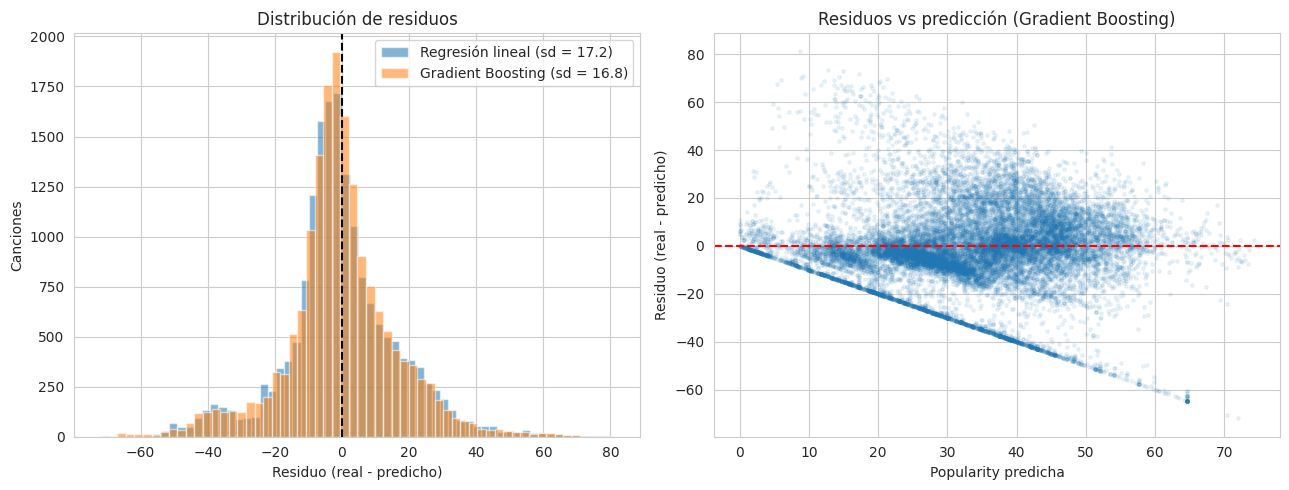

In [13]:
# Residuo = real - predicho (positivo: el modelo se queda corto; negativo: sobreestima)
res_lin = y_test.values - pred_lin
res_gb = y_test.values - pred_gb

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hist(res_lin, bins=60, alpha=0.55, label=f'Regresión lineal (sd = {res_lin.std():.1f})')
axes[0].hist(res_gb, bins=60, alpha=0.55, label=f'Gradient Boosting (sd = {res_gb.std():.1f})')
axes[0].axvline(0, color='k', linestyle='--')
axes[0].set_xlabel('Residuo (real - predicho)'); axes[0].set_ylabel('Canciones')
axes[0].set_title('Distribución de residuos'); axes[0].legend()

axes[1].scatter(pred_gb, res_gb, alpha=0.08, s=6)
axes[1].axhline(0, color='r', linestyle='--')
axes[1].set_xlabel('Popularity predicha'); axes[1].set_ylabel('Residuo (real - predicho)')
axes[1].set_title('Residuos vs predicción (Gradient Boosting)')
plt.tight_layout()
plt.savefig('../images/residuos.png', dpi=100)
plt.show()

**Lectura de los residuos** (residuo = real - predicho):

- La distribución de residuos de Gradient Boosting está centrada cerca de 0 y es apenas más estrecha que la de la regresión lineal (desv. estándar 16,8 vs 17,2).
- Los residuos **no son parejos**: hay un hombro a la izquierda (≈ -40) y una cola larga a la derecha. En el gráfico de residuos vs predicción, la **línea diagonal** corresponde a las canciones con `popularity = 0` (su residuo es exactamente `-predicción`): el modelo les asigna valores de hasta ≈ 70 aunque su popularidad real es 0. La cola derecha son las canciones muy populares, que el modelo subestima.
- Que el residuo dependa de la predicción es señal de que el modelo **se comprime hacia el promedio**.

        canciones  MAE lineal  MAE GB  sesgo GB (real - predicho)
0            1795        25.6    25.8                       -25.8
1-20         3288        10.0     9.9                        -9.1
21-40        5991         6.6     6.4                        -3.4
41-60        4771        10.2     9.6                         8.2
61-70        1280        22.7    20.6                        20.4
71-100        550        39.3    36.8                        36.8


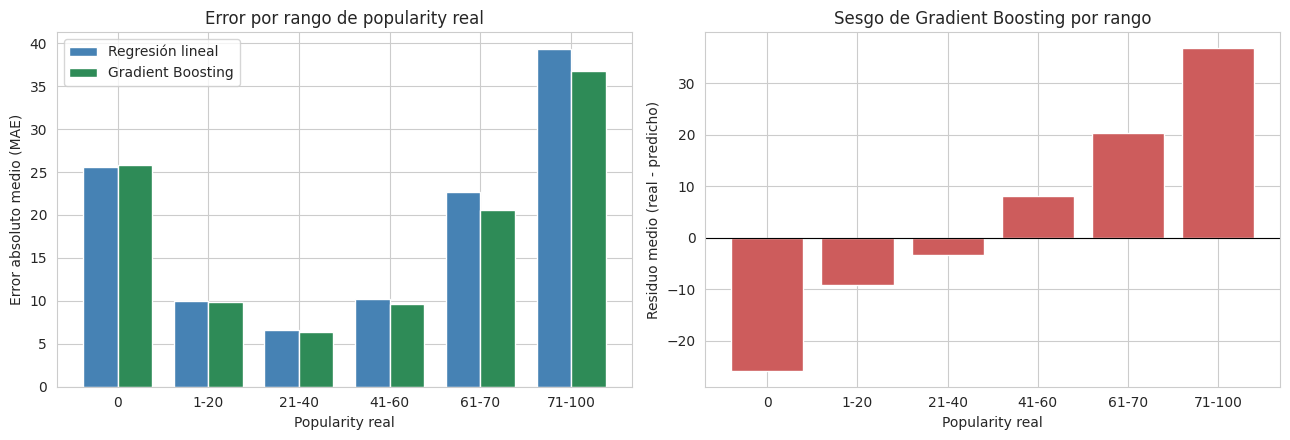

In [14]:
# ¿Dónde se equivoca el modelo? Error según el rango de popularity real
rangos = pd.cut(y_test, bins=[-1, 0, 20, 40, 60, 70, 100],
                labels=['0', '1-20', '21-40', '41-60', '61-70', '71-100'])
tabla_rangos = pd.DataFrame({
    'canciones': rangos.value_counts().sort_index(),
    'MAE lineal': pd.Series(np.abs(res_lin)).groupby(rangos.values).mean(),
    'MAE GB': pd.Series(np.abs(res_gb)).groupby(rangos.values).mean(),
    'sesgo GB (real - predicho)': pd.Series(res_gb).groupby(rangos.values).mean(),
}).round(1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
x = np.arange(len(tabla_rangos)); ancho = 0.38
axes[0].bar(x - ancho / 2, tabla_rangos['MAE lineal'], ancho, label='Regresión lineal', color='steelblue')
axes[0].bar(x + ancho / 2, tabla_rangos['MAE GB'], ancho, label='Gradient Boosting', color='seagreen')
axes[0].set_xticks(x); axes[0].set_xticklabels(tabla_rangos.index)
axes[0].set_xlabel('Popularity real'); axes[0].set_ylabel('Error absoluto medio (MAE)')
axes[0].set_title('Error por rango de popularity real'); axes[0].legend()

axes[1].bar(x, tabla_rangos['sesgo GB (real - predicho)'], color='indianred')
axes[1].axhline(0, color='k', linewidth=0.8)
axes[1].set_xticks(x); axes[1].set_xticklabels(tabla_rangos.index)
axes[1].set_xlabel('Popularity real'); axes[1].set_ylabel('Residuo medio (real - predicho)')
axes[1].set_title('Sesgo de Gradient Boosting por rango')
plt.tight_layout()
plt.savefig('../images/error_por_rango.png', dpi=100)
plt.show()
print(tabla_rangos.to_string())

**Lectura del error por rango de popularity real:**

- El modelo es más confiable para canciones de popularidad media: el MAE es ≈ 6 puntos en el rango 21-40.
- El error crece en los extremos: **MAE ≈ 26 puntos cuando `popularity = 0` y ≈ 37 puntos en las canciones top (71-100)**.
- El sesgo (panel derecho) cambia de signo: el modelo **sobreestima** las canciones de popularidad 0 (sesgo -25,8) y **subestima** las muy populares (sesgo +36,8). Es el mismo efecto de "regresión hacia el promedio" que explica el bajo recall del KPI.
- **Implicancia para el negocio:** el modelo sirve para decidir entre canciones "medias" y ordenar candidatas, pero no debe usarse para descartar una canción por tener predicción baja ni para asegurar un éxito. Las canciones con `popularity = 0` se analizan en la sección 6.7.

### 6.5 Importancia de variables

Se usa **importancia por permutación**: cuánto empeora el RMSE al desordenar una variable (mayor valor = más importante).

genre_iranian           0.713
genre_latin             0.565
genre_romance           0.383
genre_kids              0.383
genre_country           0.293
genre_detroit-techno    0.276
genre_rock              0.198
genre_pop-film          0.197
genre_soul              0.193
genre_classical         0.188
genre_chicago-house     0.173
loudness                0.168
genre_chill             0.159
genre_k-pop             0.157
genre_grindcore         0.148
dtype: float64


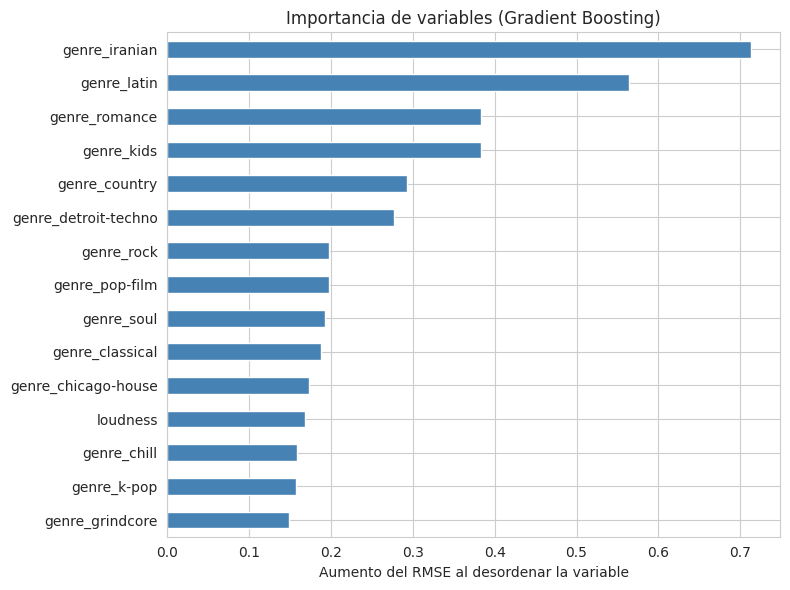

In [15]:
muestra = X_test.sample(5000, random_state=RANDOM_STATE)
imp = permutation_importance(gb, muestra, y_test.loc[muestra.index], n_repeats=3,
                             random_state=RANDOM_STATE, scoring='neg_root_mean_squared_error', n_jobs=-1)
importancia = pd.Series(imp.importances_mean, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 6))
importancia.head(15).sort_values().plot(kind='barh', color='steelblue')
plt.title('Importancia de variables (Gradient Boosting)')
plt.xlabel('Aumento del RMSE al desordenar la variable')
plt.tight_layout()
plt.savefig('../images/importancia_variables.png', dpi=100)
plt.show()
print(importancia.head(15).round(3))

**Interpretación:**
- **14 de las 15 variables más importantes son géneros**; la única audio feature entre ellas es `loudness` (puesto 12). Aparecen géneros muy distintos en popularidad promedio: `iranian`, `latin` y `romance` (muy baja) y `k-pop` (alta). Saber el género dice mucho sobre qué tan popular será una canción, incluso para artistas que el modelo no ha visto.
- Con la partición por artista las audio features por sí solas pesan poco: después de `loudness` vienen `energy` (puesto 19) y `danceability` (27); `key` casi no aporta (puesto 119 de 128).
- **Recomendación:** la popularidad depende mucho del contexto de género; conviene evaluar las canciones **dentro de su género** y no solo comparando todo el catálogo. Importancia no implica causalidad; además, parte de la importancia de `iranian`, `latin` y `romance` viene de la alta proporción de canciones con `popularity = 0` en esos géneros (sección 6.7).

**Coeficientes de la regresión lineal.** Se eligió la regresión lineal por ser interpretable; aquí se muestran sus coeficientes. En los géneros (columnas 0/1) el coeficiente es el cambio en puntos de `popularity` por pertenecer al género; en las audio features se multiplica por la desviación estándar para que sean comparables entre sí.

romance          -37.0
iranian          -35.9
latin            -29.7
jazz             -26.8
detroit-techno   -26.6
chicago-house    -26.4
classical        -24.2
idm              -23.2
sertanejo          8.2
piano             10.3
indian            10.6
grunge            10.8
pop               11.4
chill             11.9
pop-film          14.9
k-pop             14.9

energy             -0.85
valence            -0.68
speechiness        -0.61
mode               -0.50
instrumentalness   -0.45
acousticness       -0.44
liveness           -0.35
duration_ms        -0.01
key                -0.01
tempo               0.11
time_signature      0.22
loudness            0.49
explicit            0.62
danceability        0.78


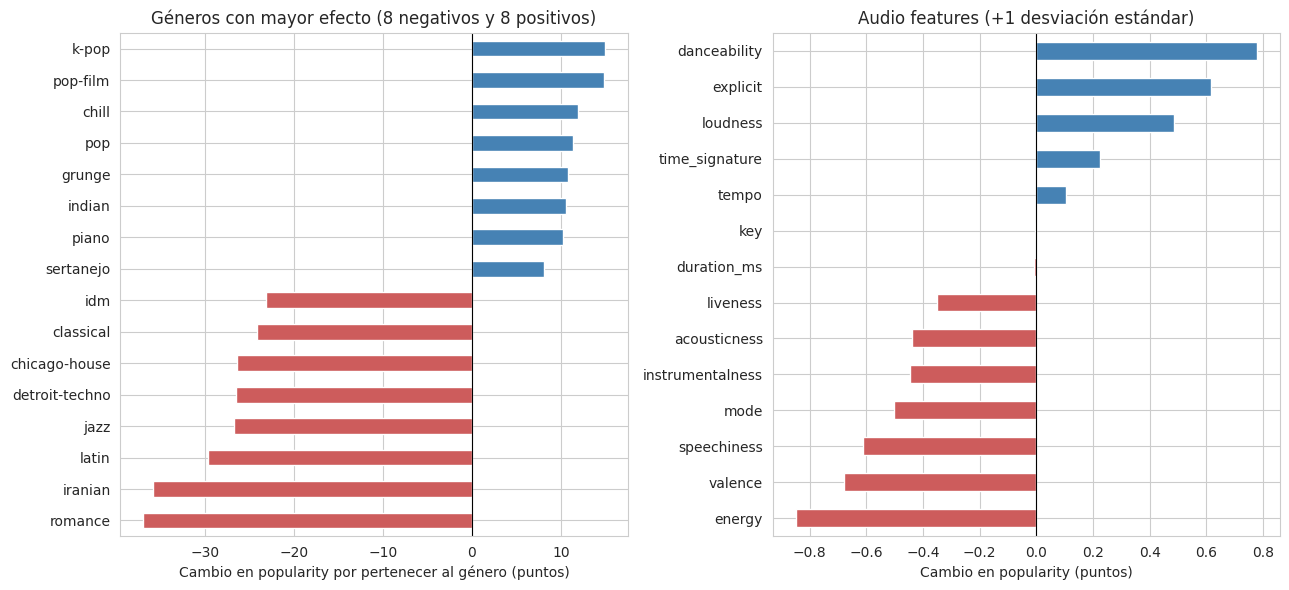

In [16]:
# Coeficientes de la regresión lineal (el modelo se justificó "por interpretable")
coef = pd.Series(lin.coef_, index=X.columns)
aud = [c for c in X.columns if c not in genre_cols]

# Géneros: puntos de popularity que suma o resta pertenecer al género (mismas condiciones en lo demás)
coef_gen = coef[genre_cols].sort_values()
gen_sel = pd.concat([coef_gen.head(8), coef_gen.tail(8)])
gen_sel.index = [i.replace('genre_', '') for i in gen_sel.index]
# Audio features: puntos de popularity por cada +1 desviación estándar del predictor (comparables entre sí)
efecto_aud = (coef[aud] * X_train[aud].std()).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
gen_sel.plot(kind='barh', ax=axes[0], color=['indianred' if v < 0 else 'steelblue' for v in gen_sel.values])
axes[0].axvline(0, color='k', linewidth=0.8)
axes[0].set_title('Géneros con mayor efecto (8 negativos y 8 positivos)')
axes[0].set_xlabel('Cambio en popularity por pertenecer al género (puntos)')
efecto_aud.plot(kind='barh', ax=axes[1], color=['indianred' if v < 0 else 'steelblue' for v in efecto_aud.values])
axes[1].axvline(0, color='k', linewidth=0.8)
axes[1].set_title('Audio features (+1 desviación estándar)')
axes[1].set_xlabel('Cambio en popularity (puntos)')
plt.tight_layout()
plt.savefig('../images/coeficientes_regresion_lineal.png', dpi=100)
plt.show()
print(gen_sel.round(1).to_string())
print()
print(efecto_aud.round(2).to_string())

**Lectura de los coeficientes:**
- **El género pesa mucho más que las audio features.** Pertenecer a `romance`, `iranian` o `latin` resta ≈ 30-37 puntos de popularidad respecto de otras canciones (con las demás variables iguales), mientras que `pop-film` o `k-pop` suman ≈ 15. En cambio, ninguna audio feature mueve la popularidad más de ≈ 0,9 puntos por cada desviación estándar (`danceability` +0,78, `energy` -0,85).
- Los efectos de audio son pequeños pero tienen sentido: más bailable, con contenido explícito y más fuerte (`loudness`) se asocia a algo más de popularidad; más energía, valencia (positividad) y habla (`speechiness`) se asocia a algo menos, una vez descontado el género.
- Los géneros con más ceros (`romance`, `iranian`, `latin`, `jazz`) tienen los coeficientes más negativos, coherente con la sensibilidad a `popularity = 0` de la sección 6.7.
- `key` tiene un efecto prácticamente nulo (-0,01 puntos por desviación estándar), por lo que tratarla como numérica no afecta el resultado.

### 6.6 Guardado de modelos

In [17]:
joblib.dump(lin, '../models/regresion_lineal.joblib')
joblib.dump(gb, '../models/gradient_boosting.joblib')
joblib.dump(list(X.columns), '../models/columnas_modelo.joblib')
tabla.to_csv('../models/metricas_modelos.csv', index_label='modelo')

### 6.7 Sensibilidad: ¿qué pasa si se excluyen las canciones con `popularity = 0`?

En el EDA (sección 3.5) se vio que los ceros se concentran en ciertos géneros (`iranian`, `latin`, `romance`, `jazz`...) y podrían ser un artefacto de cómo se recolectó el dataset. Como `iranian`, `latin` y `romance` aparecen entre las variables más importantes, se comprueba cuánto de ese resultado depende de esas filas.

**Diseño:** se mantienen los modelos finales tal como están (los ceros siguen en el entrenamiento oficial) y se hace un experimento aparte, con la misma partición por artista y los mismos hiperparámetros: se reentrena Gradient Boosting **sin las filas con `popularity = 0`** y se compara (1) el error sobre las canciones con `popularity > 0` y (2) la importancia de variables.

In [18]:
nz_train = (y_train > 0).values
nz_test = (y_test > 0).values

gb_sin0 = HistGradientBoostingRegressor(**gb.get_params()).fit(X_train[nz_train], y_train[nz_train])
pred_gb_sin0 = np.clip(gb_sin0.predict(X_test[nz_test]), 0, 100)

sensibilidad = pd.DataFrame({
    'GB completo | prueba completa': metricas(y_test, pred_gb),
    'GB completo | prueba sin ceros': metricas(y_test[nz_test], pred_gb[nz_test]),
    'GB sin ceros | prueba sin ceros': metricas(y_test[nz_test], pred_gb_sin0),
}).T.round(3)

print(f'Canciones con popularity = 0: entrenamiento {(~nz_train).mean():.1%} | prueba {(~nz_test).mean():.1%}')
sensibilidad

Canciones con popularity = 0: entrenamiento 10.6% | prueba 10.2%


,RMSE,MAE,R2
GB completo | prueba completa,16.844,11.847,0.345
GB completo | prueba sin ceros,14.702,10.275,0.375
GB sin ceros | prueba sin ceros,13.656,9.568,0.461


               Importancia (completo)  Importancia (sin ceros)  Puesto (completo)  Puesto (sin ceros)
genre_iranian                   0.713                    0.129                  1                  19
genre_latin                     0.565                    0.179                  2                  12
genre_romance                   0.383                    0.286                  3                   4
genre_k-pop                     0.157                    0.203                 14                   9

Top 10 sin ceros: [('genre_kids', 0.599), ('genre_detroit-techno', 0.508), ('instrumentalness', 0.435), ('genre_romance', 0.286), ('genre_chicago-house', 0.279), ('genre_idm', 0.242), ('genre_tango', 0.228), ('genre_pop-film', 0.207), ('genre_k-pop', 0.203), ('genre_chill', 0.194)]


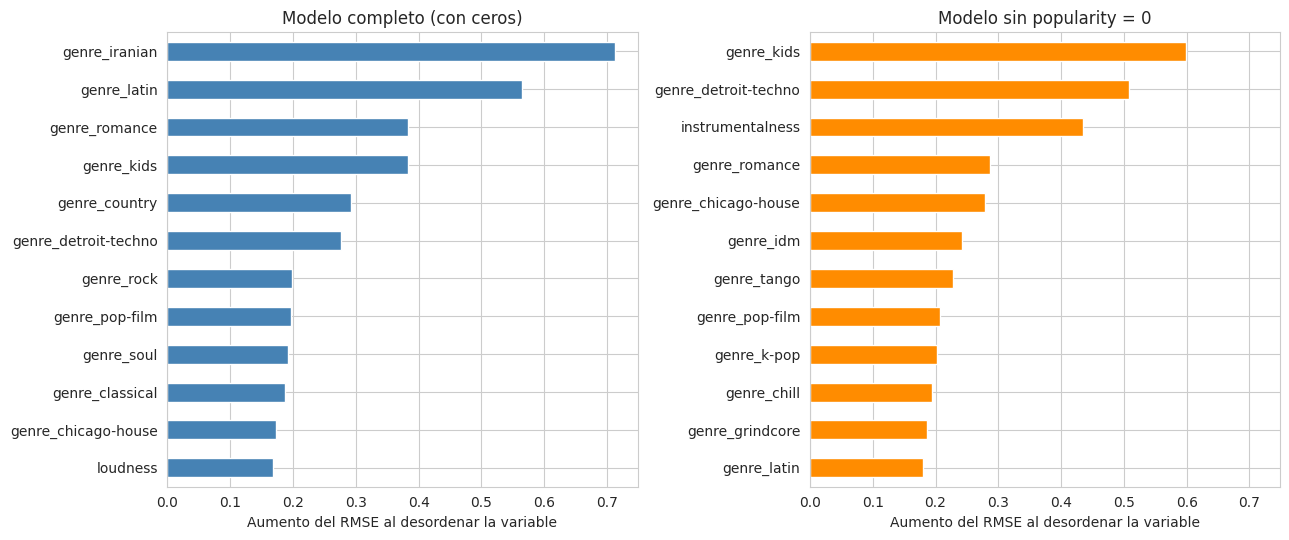

In [19]:
muestra_sin0 = X_test[nz_test].sample(5000, random_state=RANDOM_STATE)
imp0 = permutation_importance(gb_sin0, muestra_sin0, y_test.loc[muestra_sin0.index], n_repeats=3,
                              random_state=RANDOM_STATE, scoring='neg_root_mean_squared_error', n_jobs=-1)
importancia_sin0 = pd.Series(imp0.importances_mean, index=X.columns).sort_values(ascending=False)

comparacion = pd.DataFrame({'Importancia (completo)': importancia, 'Importancia (sin ceros)': importancia_sin0})
comparacion['Puesto (completo)'] = comparacion['Importancia (completo)'].rank(ascending=False).astype(int)
comparacion['Puesto (sin ceros)'] = comparacion['Importancia (sin ceros)'].rank(ascending=False).astype(int)

foco = ['genre_iranian', 'genre_latin', 'genre_romance', 'genre_k-pop']
print(comparacion.loc[foco].round(3).to_string())
print('\nTop 10 sin ceros:', list(importancia_sin0.head(10).round(3).items()))

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True)
importancia.head(12).sort_values().plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].set_title('Modelo completo (con ceros)')
importancia_sin0.head(12).sort_values().plot(kind='barh', ax=axes[1], color='darkorange')
axes[1].set_title('Modelo sin popularity = 0')
for ax in axes:
    ax.set_xlabel('Aumento del RMSE al desordenar la variable')
plt.tight_layout()
plt.savefig('../images/importancia_sin_ceros.png', dpi=100)
plt.show()

**Interpretación:**
- **El desempeño no es un artefacto de los ceros.** Evaluado solo sobre canciones con `popularity > 0` (segunda fila), el modelo oficial tiene R² 0,375 y RMSE 14,70, similar al global (0,345 y 16,84). Al reentrenar sin los ceros (tercera fila) el error baja (RMSE 13,66) y el R² sube a 0,461, porque ya no tiene que explicar canciones que valen 0 sin una causa visible en los datos. Esa mejora **no es comparable** con la tabla principal: se mide sobre otra población (solo canciones con popularidad mayor a 0).
- **El peso de `iranian` y `latin` venía en gran parte de los ceros.** Su importancia cae ≈ 82% y ≈ 68% (de 0,71 a 0,13 y de 0,57 a 0,18) y pasan del puesto 1 y 2 al 19 y 12. `romance` baja menos (de 0,38 a 0,29; puesto 3 a 4) y `k-pop` incluso sube (de 0,16 a 0,20): su efecto depende menos de ese artefacto.
- **El género sigue siendo una señal dominante, pero otros géneros toman su lugar.** Los primeros puestos del modelo sin ceros son `kids` (0,60) y `detroit-techno` (0,51), que casi no tienen ceros y cuya popularidad promedio es claramente distinta del resto; además `instrumentalness` sube al tercer lugar (0,44).
- **Conclusión:** "el género es el predictor más informativo" se sostiene, pero **"el género determina la popularidad" es una frase exagerada**: una parte de lo que aprende el modelo sobre `iranian` y `latin` es dónde se concentran los ceros. Los valores exactos pueden variar levemente según la versión de scikit-learn.

## 7. Conclusiones de la etapa de modelado

1. **Gradient Boosting es el mejor modelo** (RMSE 16,84, MAE 11,85, R² 0,345), por encima de la regresión lineal (17,22 / 12,32 / 0,315) y de la línea base (20,81 / 17,48), aunque la ventaja sobre la lineal es modesta. Ampliar la búsqueda de hiperparámetros no mejoró el resultado.
2. **La partición por artista es la que corresponde al negocio** (predecir artistas nuevos). Con una partición aleatoria el R² de Gradient Boosting subiría a ≈ 0,43 por conocer al artista (sección 5.5): esa cifra sería optimista.
3. Gradient Boosting muestra **sobreajuste moderado** (R² 0,50 en entrenamiento contra 0,345 en prueba). El rendimiento tiene además un **techo** por la falta de variables como promoción, fecha de lanzamiento o trayectoria del artista.
4. Para la distribuidora, el modelo es una **herramienta de priorización** (captura ~29% de las canciones top en el 10% mejor rankeado, contra ~10% al azar), no un predictor exacto, y debe complementar el criterio de A&R.
5. La **evaluación gráfica del KPI** confirma el diagnóstico: AUC = 0,63 (GB) vs 0,59 (lineal), y un error que crece en los extremos (MAE ≈ 6 en popularidad media, ≈ 26 en `popularity = 0` y ≈ 37 en las canciones top). El modelo ordena bien lo "medio" y sub/sobreestima los extremos.
6. **El género pesa mucho más que las audio features** (coeficientes de la regresión lineal e importancia por permutación), pero **la sensibilidad a `popularity = 0` (sección 6.7)** muestra que `iranian` y `latin` pierden ≈ 82% y ≈ 68% de su importancia sin esas canciones. El género es una señal fuerte, no un determinante de la popularidad; los ceros podrían ser un artefacto del dataset.
7. Las predicciones se recortan al rango 0-100 y los valores inválidos de las audio features (≈ 0,35% de las canciones) se documentan y conservan (`01_preparacion_datos.ipynb`, sección 2.4.1).
8. Siguiente etapa: **aprendizaje no supervisado** (clustering) para descubrir segmentos de canciones y relacionarlos con la popularidad (`04_clustering.ipynb`).